Using device: cuda


Processing...
Done!



Dataset: Cornell  (183 nodes, 5 classes, 1703 feats)
  Run 1/10 ...
    GENTAG (w/o Msg ReLU)       75.68%
    GENTAG (Fixed Comb)         70.27%
    GENTAG (K=1)                75.68%
    GENTAG (K=2)                78.38%
    GENTAG (No Input Drop)      78.38%
  Run 2/10 ...
    GENTAG (w/o Msg ReLU)       72.97%
    GENTAG (Fixed Comb)         67.57%
    GENTAG (K=1)                70.27%
    GENTAG (K=2)                70.27%
    GENTAG (No Input Drop)      72.97%
  Run 3/10 ...
    GENTAG (w/o Msg ReLU)       78.38%
    GENTAG (Fixed Comb)         72.97%
    GENTAG (K=1)                83.78%
    GENTAG (K=2)                78.38%
    GENTAG (No Input Drop)      78.38%
  Run 4/10 ...
    GENTAG (w/o Msg ReLU)       72.97%
    GENTAG (Fixed Comb)         70.27%
    GENTAG (K=1)                75.68%
    GENTAG (K=2)                72.97%
    GENTAG (No Input Drop)      70.27%
  Run 5/10 ...
    GENTAG (w/o Msg ReLU)       78.38%
    GENTAG (Fixed Comb)         72.97%
    GENTAG (K


Dataset: Texas  (183 nodes, 5 classes, 1703 feats)
  Run 1/10 ...


Processing...
Done!


    GENTAG (w/o Msg ReLU)       75.68%
    GENTAG (Fixed Comb)         75.68%
    GENTAG (K=1)                75.68%
    GENTAG (K=2)                75.68%
    GENTAG (No Input Drop)      75.68%
  Run 2/10 ...
    GENTAG (w/o Msg ReLU)       78.38%
    GENTAG (Fixed Comb)         75.68%
    GENTAG (K=1)                78.38%
    GENTAG (K=2)                83.78%
    GENTAG (No Input Drop)      78.38%
  Run 3/10 ...
    GENTAG (w/o Msg ReLU)       67.57%
    GENTAG (Fixed Comb)         67.57%
    GENTAG (K=1)                81.08%
    GENTAG (K=2)                75.68%
    GENTAG (No Input Drop)      72.97%
  Run 4/10 ...
    GENTAG (w/o Msg ReLU)       78.38%
    GENTAG (Fixed Comb)         75.68%
    GENTAG (K=1)                89.19%
    GENTAG (K=2)                75.68%
    GENTAG (No Input Drop)      72.97%
  Run 5/10 ...
    GENTAG (w/o Msg ReLU)       72.97%
    GENTAG (Fixed Comb)         75.68%
    GENTAG (K=1)                83.78%
    GENTAG (K=2)                75.68%
    

Processing...



Dataset: Wisconsin  (251 nodes, 5 classes, 1703 feats)
  Run 1/10 ...


Done!


    GENTAG (w/o Msg ReLU)       76.47%
    GENTAG (Fixed Comb)         76.47%
    GENTAG (K=1)                82.35%
    GENTAG (K=2)                82.35%
    GENTAG (No Input Drop)      76.47%
  Run 2/10 ...
    GENTAG (w/o Msg ReLU)       78.43%
    GENTAG (Fixed Comb)         82.35%
    GENTAG (K=1)                84.31%
    GENTAG (K=2)                78.43%
    GENTAG (No Input Drop)      80.39%
  Run 3/10 ...
    GENTAG (w/o Msg ReLU)       84.31%
    GENTAG (Fixed Comb)         84.31%
    GENTAG (K=1)                88.24%
    GENTAG (K=2)                88.24%
    GENTAG (No Input Drop)      84.31%
  Run 4/10 ...
    GENTAG (w/o Msg ReLU)       88.24%
    GENTAG (Fixed Comb)         82.35%
    GENTAG (K=1)                90.20%
    GENTAG (K=2)                86.27%
    GENTAG (No Input Drop)      88.24%
  Run 5/10 ...
    GENTAG (w/o Msg ReLU)       82.35%
    GENTAG (Fixed Comb)         78.43%
    GENTAG (K=1)                78.43%
    GENTAG (K=2)                80.39%
    

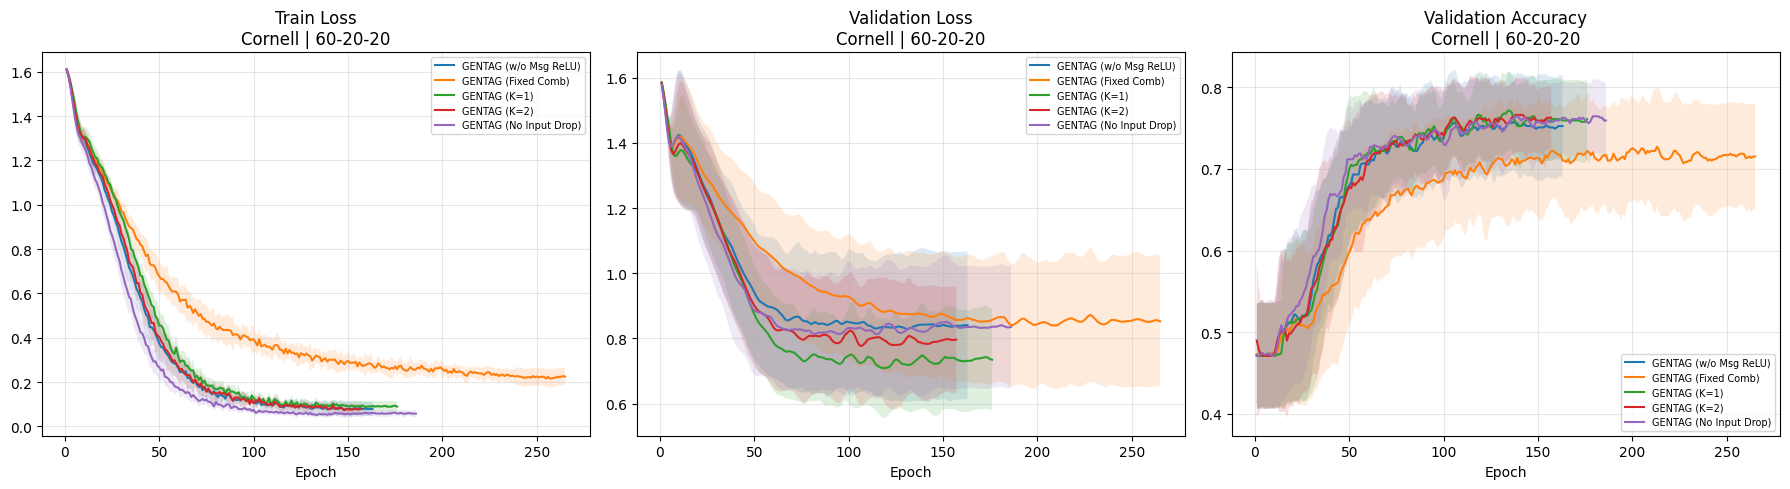

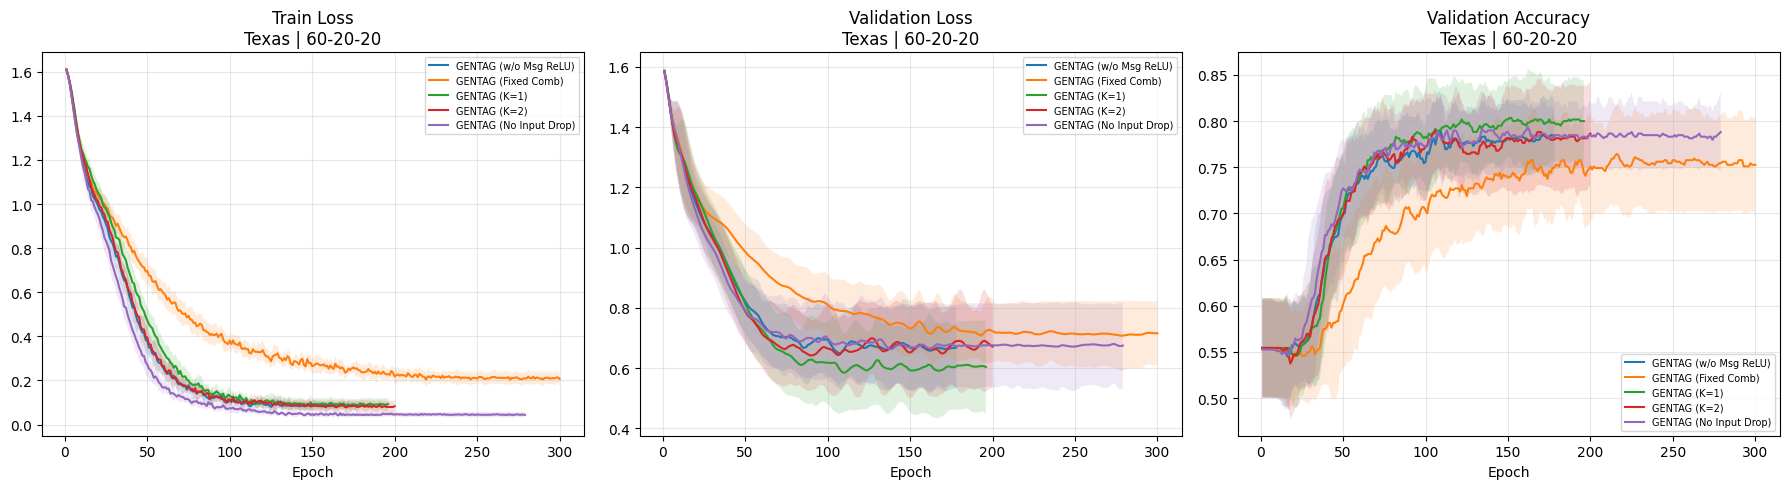

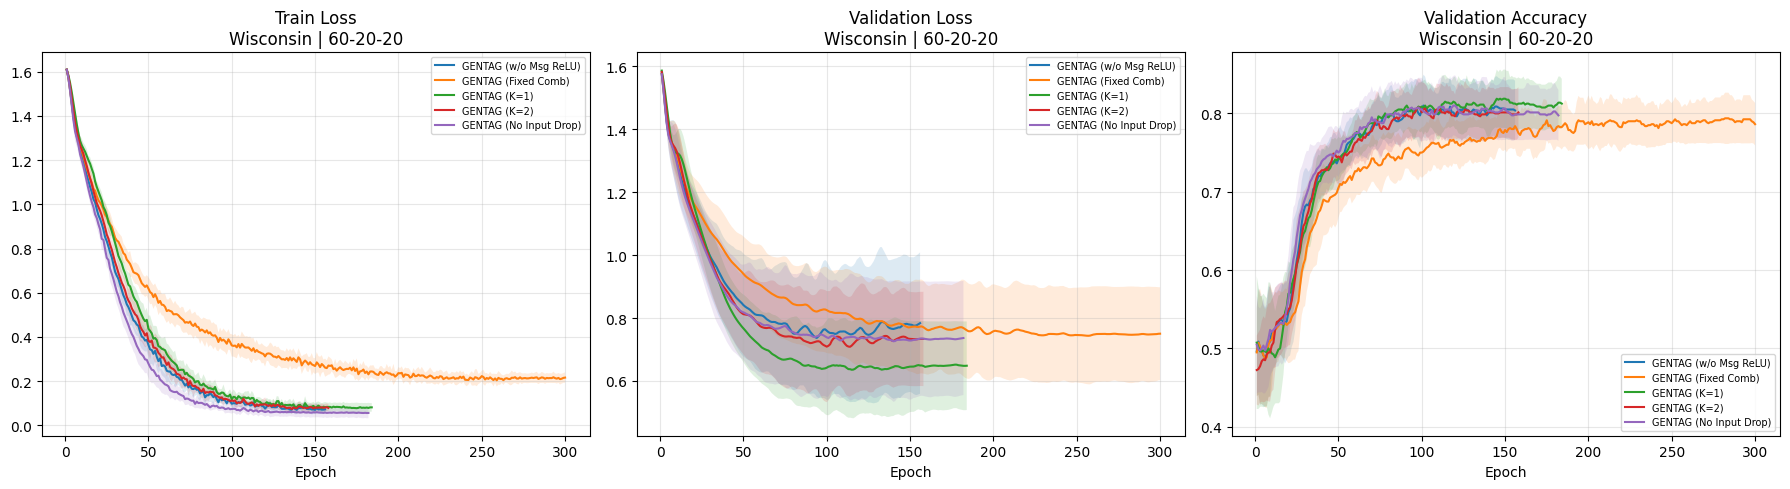


Total time: 224.0s


In [ ]:
#ablation study
!pip install torch_geometric -q

import os
import random
import json
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import Linear
import matplotlib.pyplot as plt

from torch_geometric.datasets import WebKB
from torch_geometric.transforms import NormalizeFeatures
from torch_geometric.nn import MessagePassing
from torch_geometric.nn.conv.gcn_conv import gcn_norm
from torch_geometric.nn.inits import zeros
from torch_geometric.utils import spmm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

SEED = 42

# ---------- hyper-parameters ----------
HIDDEN_DIM   = 64
DROPOUT      = 0.5
LR           = 0.01
WEIGHT_DECAY = 5e-4
MAX_EPOCHS   = 300
PATIENCE     = 30
NUM_RUNS     = 10

# ---------- fairness switches ----------
SELECT_BY          = 'val_loss'
NO_DECAY_HOP_COEFS = True

# ---------- architecture constants ----------
K_TAG = 3


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ------------------------------------------------------------
# GENTAG layer
# ------------------------------------------------------------
class TAGConv1(MessagePassing):
    def __init__(self, in_channels, out_channels, K=3, bias=True, normalize=True,
                 use_mlp=False, use_message_relu=True, eps=1e-7,
                 fixed_comb=False, **kwargs):
        kwargs.setdefault('aggr', 'add')
        super().__init__(**kwargs)

        self.K = K
        self.normalize = normalize
        self.use_mlp = use_mlp
        self.use_message_relu = use_message_relu
        self.eps = eps
        self.fixed_comb = fixed_comb

        self.lins = nn.ModuleList([
            Linear(in_channels, out_channels, bias=False) for _ in range(K + 1)
        ])

        if fixed_comb:
            self.register_buffer('comb', torch.ones(K + 1))
        else:
            self.comb = nn.Parameter(torch.ones(K + 1))

        if bias:
            self.bias = nn.Parameter(torch.zeros(out_channels))
        else:
            self.register_parameter('bias', None)

        self.mlp = nn.Sequential(Linear(out_channels, out_channels), nn.ReLU()) if use_mlp else nn.Identity()
        self.reset_parameters()

    def reset_parameters(self):
        for lin in self.lins:
            lin.reset_parameters()
        if not self.fixed_comb:
            nn.init.ones_(self.comb)
        if self.bias is not None:
            zeros(self.bias)

    def forward(self, x, edge_index, edge_weight=None):
        if self.normalize:
            edge_index, edge_weight = gcn_norm(
                edge_index, edge_weight, x.size(self.node_dim),
                improved=False, add_self_loops=False,
                flow=self.flow, dtype=x.dtype
            )

        out = self.comb[0] * self.lins[0](x)
        h = x
        for k in range(1, self.K + 1):
            h = self.propagate(edge_index, x=h, edge_weight=edge_weight)
            out = out + self.comb[k] * self.lins[k](h)

        if self.bias is not None:
            out = out + self.bias
        return self.mlp(out)

    def message(self, x_j, edge_weight):
        msg = x_j if edge_weight is None else edge_weight.view(-1, 1) * x_j
        if self.use_message_relu:
            return msg.relu() + self.eps
        return msg

    def message_and_aggregate(self, adj_t, x):
        return spmm(adj_t, x, reduce=self.aggr)


class GENTAG(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels,
                 K=K_TAG, use_message_relu=True, fixed_comb=False,
                 input_dropout=True):
        super().__init__()
        self.input_dropout = input_dropout
        self.conv1 = TAGConv1(in_channels, hidden_channels, K=K,
                              use_mlp=False, use_message_relu=use_message_relu,
                              fixed_comb=fixed_comb, eps=1e-7)
        self.conv2 = TAGConv1(hidden_channels, out_channels, K=K,
                              use_mlp=False, use_message_relu=use_message_relu,
                              fixed_comb=fixed_comb, eps=1e-7)

    def forward(self, x, edge_index):
        if self.input_dropout:
            x = F.dropout(x, p=DROPOUT, training=self.training)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=DROPOUT, training=self.training)
        return self.conv2(x, edge_index)


# ------------------------------------------------------------
# Ablation variants
# ------------------------------------------------------------
ABLATIONS = {
    'GENTAG (w/o Msg ReLU)':  dict(use_message_relu=False, fixed_comb=False, K=3, input_dropout=True),
    'GENTAG (Fixed Comb)':    dict(use_message_relu=True,  fixed_comb=True,  K=3, input_dropout=True),
    'GENTAG (K=1)':           dict(use_message_relu=True,  fixed_comb=False, K=1, input_dropout=True),
    'GENTAG (K=2)':           dict(use_message_relu=True,  fixed_comb=False, K=2, input_dropout=True),
    'GENTAG (No Input Drop)': dict(use_message_relu=True,  fixed_comb=False, K=3, input_dropout=False),
}


def make_optimizer(model, lr, weight_decay):
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if NO_DECAY_HOP_COEFS and ('comb' in name):
            no_decay.append(param)
        else:
            decay.append(param)
    groups = [{'params': decay, 'weight_decay': weight_decay}]
    if no_decay:
        groups.append({'params': no_decay, 'weight_decay': 0.0})
    return torch.optim.Adam(groups, lr=lr)


def train_one_epoch(model, data, optimizer, criterion):
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()


@torch.no_grad()
def evaluate(model, data, criterion):
    model.eval()
    out = model(data.x, data.edge_index)
    pred = out.argmax(dim=1)
    val_loss = criterion(out[data.val_mask], data.y[data.val_mask]).item()
    val_acc  = (pred[data.val_mask]  == data.y[data.val_mask]).float().mean().item()
    test_acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean().item()
    return val_loss, val_acc, test_acc


def run_with_early_stopping(model, data):
    optimizer = make_optimizer(model, LR, WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()

    best = {'val_loss': float('inf'), 'val_acc': 0.0, 'test_acc': 0.0, 'epoch': 0}
    patience_counter = 0

    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss = train_one_epoch(model, data, optimizer, criterion)
        val_loss, val_acc, test_acc = evaluate(model, data, criterion)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        improved = (val_loss < best['val_loss']) if SELECT_BY == 'val_loss' else (val_acc > best['val_acc'])
        if improved:
            best = {'val_loss': val_loss, 'val_acc': val_acc, 'test_acc': test_acc, 'epoch': epoch}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                break

    return best['val_acc'], best['test_acc'], history


# ------------------------------------------------------------
# Dataset helpers
# ------------------------------------------------------------
DATASETS = ['Cornell', 'Texas', 'Wisconsin']


def load_dataset(name):
    return WebKB(root=f'./data/{name}', name=name, transform=NormalizeFeatures())


def get_data(raw_data, run):

    data = raw_data.clone()
    data.train_mask = data.train_mask[:, run % data.train_mask.size(1)]
    data.val_mask   = data.val_mask[:,   run % data.val_mask.size(1)]
    data.test_mask  = data.test_mask[:,  run % data.test_mask.size(1)]
    return data.to(device)


# ------------------------------------------------------------
# Main experiment
# ------------------------------------------------------------
all_results   = {}
all_histories = {}
t0 = time.time()

for ds_name in DATASETS:
    dataset  = load_dataset(ds_name)
    raw_data = dataset[0]
    all_results[ds_name]   = {}
    all_histories[ds_name] = {}

    print(f"\n{'='*70}")
    print(f"Dataset: {ds_name}  ({raw_data.num_nodes} nodes, {dataset.num_classes} classes, {dataset.num_features} feats)")
    print(f"{'='*70}")

    split_results   = {name: [] for name in ABLATIONS}
    split_histories = {name: [] for name in ABLATIONS}

    for run in range(NUM_RUNS):
        data = get_data(raw_data, run)
        print(f"  Run {run+1}/{NUM_RUNS} ...", flush=True)

        for abl_name, kwargs in ABLATIONS.items():
            set_seed(SEED + run)
            model = GENTAG(dataset.num_features, HIDDEN_DIM, dataset.num_classes, **kwargs).to(device)
            _, test_acc, history = run_with_early_stopping(model, data)

            split_results[abl_name].append(test_acc * 100)
            split_histories[abl_name].append(history)
            print(f"    {abl_name:<26} {test_acc*100:6.2f}%", flush=True)

        del data
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    all_results[ds_name]   = {}
    all_histories[ds_name] = split_histories

    print(f"\n--- {ds_name} | 60-20-20 | {time.time()-t0:.0f}s elapsed ---")
    for abl_name, accs in split_results.items():
        accs = np.array(accs)
        mean, std = float(accs.mean()), float(accs.std(ddof=1))
        all_results[ds_name][abl_name] = (mean, std)
        print(f"{abl_name:<26} {mean:6.2f} ± {std:5.2f}")



# Final tables

print("\n\n" + "="*70)
print("FINAL RESULTS (Test Accuracy %)")
print("="*70)

for ds, d in all_results.items():
    print(f"\n### {ds}")
    df = pd.DataFrame({
        'Accuracy (%)': {m: f"{mu:.2f} ± {sd:.2f}" for m, (mu, sd) in d.items()}
    })
    print(df.to_string())

# Save results
with open('results_gentag_ablation_webkb.json', 'w') as f:
    json.dump(all_results, f, indent=2)
print("\nResults saved to results_gentag_ablation_webkb.json")


# ------------------------------------------------------------
# Plot average curves
# ------------------------------------------------------------
def pad_and_average(histories, key):
    max_len = max(len(h[key]) for h in histories)
    padded = []
    for h in histories:
        arr = np.array(h[key])
        if len(arr) < max_len:
            arr = np.pad(arr, (0, max_len - len(arr)), mode='edge')
        padded.append(arr)
    return np.mean(padded, axis=0), np.std(padded, axis=0)


def plot_curves(histories_dict, dataset_name):
    models = list(histories_dict.keys())
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    metrics = [
        ('train_loss', 'Train Loss'),
        ('val_loss',   'Validation Loss'),
        ('val_acc',    'Validation Accuracy')
    ]

    for ax, (key, title) in zip(axes, metrics):
        for model_name in models:
            mean, std = pad_and_average(histories_dict[model_name], key)
            epochs = np.arange(1, len(mean) + 1)
            ax.plot(epochs, mean, label=model_name)
            ax.fill_between(epochs, mean - std, mean + std, alpha=0.15)
        ax.set_title(f"{title}\n{dataset_name} | 60-20-20")
        ax.set_xlabel("Epoch")
        ax.legend(fontsize=7)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


for ds_name in all_histories:
    plot_curves(all_histories[ds_name], ds_name)

print(f"\nTotal time: {time.time() - t0:.1f}s")

Using device: cuda



Dataset: Citeseer  (4230 nodes, 6 classes, 602 feats)
  Run 1/10 ...


Processing...
Done!


    GENTAG (w/o Msg ReLU)       94.92%
    GENTAG (Fixed Comb)         95.63%
    GENTAG (K=1)                94.09%
    GENTAG (K=2)                94.33%
    GENTAG (No Input Drop)      95.15%
  Run 2/10 ...
    GENTAG (w/o Msg ReLU)       95.27%
    GENTAG (Fixed Comb)         95.04%
    GENTAG (K=1)                94.44%
    GENTAG (K=2)                94.80%
    GENTAG (No Input Drop)      96.22%
  Run 3/10 ...
    GENTAG (w/o Msg ReLU)       94.33%
    GENTAG (Fixed Comb)         94.33%
    GENTAG (K=1)                93.74%
    GENTAG (K=2)                94.09%
    GENTAG (No Input Drop)      94.80%
  Run 4/10 ...
    GENTAG (w/o Msg ReLU)       96.22%
    GENTAG (Fixed Comb)         95.27%
    GENTAG (K=1)                95.74%
    GENTAG (K=2)                96.22%
    GENTAG (No Input Drop)      95.86%
  Run 5/10 ...
    GENTAG (w/o Msg ReLU)       95.63%
    GENTAG (Fixed Comb)         95.63%
    GENTAG (K=1)                94.33%
    GENTAG (K=2)                95.98%
    

Processing...
Done!



Dataset: Pubmed  (19717 nodes, 3 classes, 500 feats)
  Run 1/10 ...
    GENTAG (w/o Msg ReLU)       89.68%
    GENTAG (Fixed Comb)         88.67%
    GENTAG (K=1)                89.60%
    GENTAG (K=2)                89.71%
    GENTAG (No Input Drop)      90.14%
  Run 2/10 ...
    GENTAG (w/o Msg ReLU)       90.16%
    GENTAG (Fixed Comb)         89.00%
    GENTAG (K=1)                90.21%
    GENTAG (K=2)                90.21%
    GENTAG (No Input Drop)      91.02%
  Run 3/10 ...
    GENTAG (w/o Msg ReLU)       89.96%
    GENTAG (Fixed Comb)         88.31%
    GENTAG (K=1)                89.55%
    GENTAG (K=2)                89.76%
    GENTAG (No Input Drop)      90.64%
  Run 4/10 ...
    GENTAG (w/o Msg ReLU)       89.53%
    GENTAG (Fixed Comb)         88.06%
    GENTAG (K=1)                89.53%
    GENTAG (K=2)                89.33%
    GENTAG (No Input Drop)      89.91%
  Run 5/10 ...
    GENTAG (w/o Msg ReLU)       89.07%
    GENTAG (Fixed Comb)         88.03%
    GENTAG (K

... (2 outputs left out)

Processing...



Dataset: Computers  (13752 nodes, 10 classes, 767 feats)
  Run 1/10 ...


Done!


    GENTAG (w/o Msg ReLU)       90.99%
    GENTAG (Fixed Comb)         81.10%
    GENTAG (K=1)                91.09%
    GENTAG (K=2)                90.69%
    GENTAG (No Input Drop)      90.91%
  Run 2/10 ...
    GENTAG (w/o Msg ReLU)       89.53%
    GENTAG (Fixed Comb)         80.95%
    GENTAG (K=1)                89.46%
    GENTAG (K=2)                90.66%
    GENTAG (No Input Drop)      90.62%
  Run 3/10 ...
    GENTAG (w/o Msg ReLU)       89.82%
    GENTAG (Fixed Comb)         81.06%
    GENTAG (K=1)                89.89%
    GENTAG (K=2)                90.80%
    GENTAG (No Input Drop)      90.33%
  Run 4/10 ...
    GENTAG (w/o Msg ReLU)       91.38%
    GENTAG (Fixed Comb)         80.66%
    GENTAG (K=1)                91.57%
    GENTAG (K=2)                91.57%
    GENTAG (No Input Drop)      91.60%
  Run 5/10 ...
    GENTAG (w/o Msg ReLU)       90.73%
    GENTAG (Fixed Comb)         80.41%
    GENTAG (K=1)                90.29%
    GENTAG (K=2)                90.80%
    

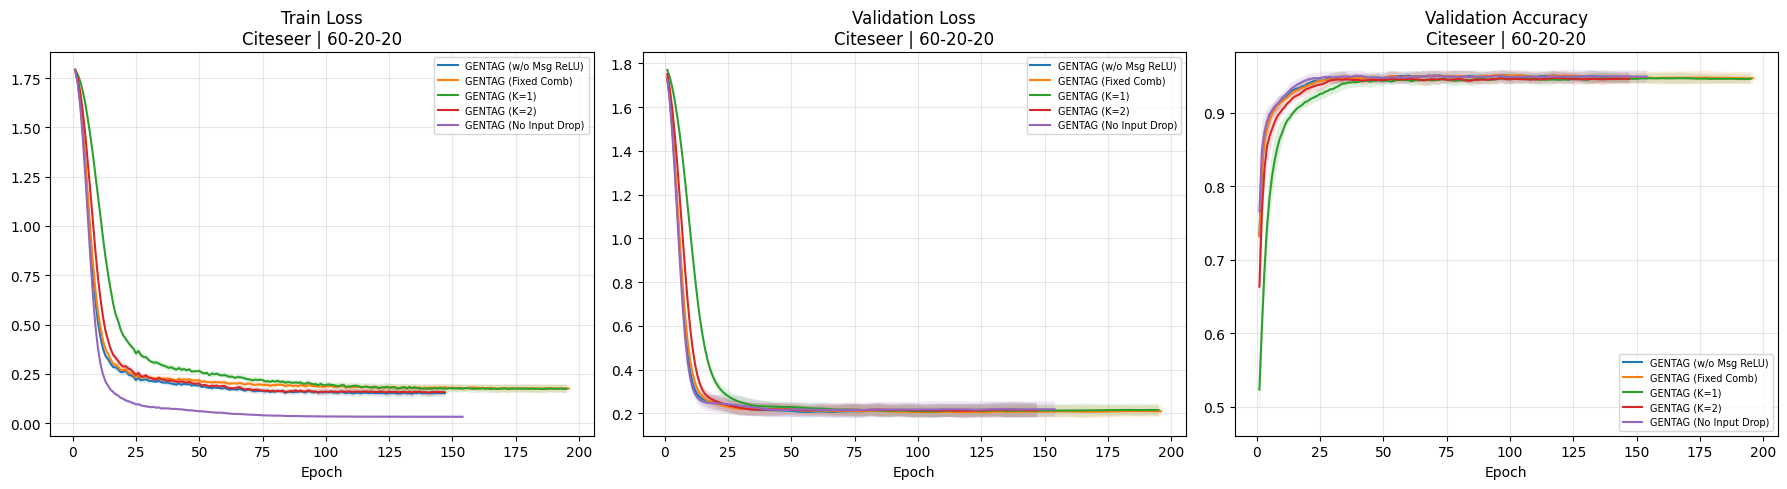

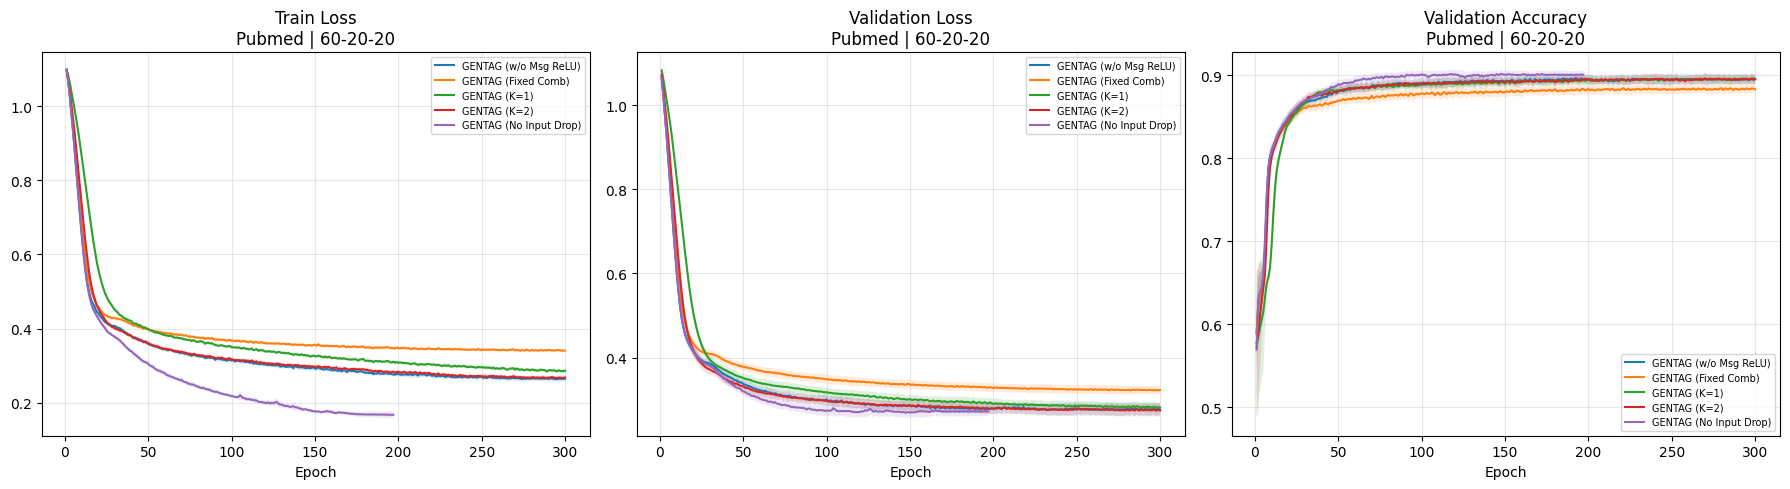

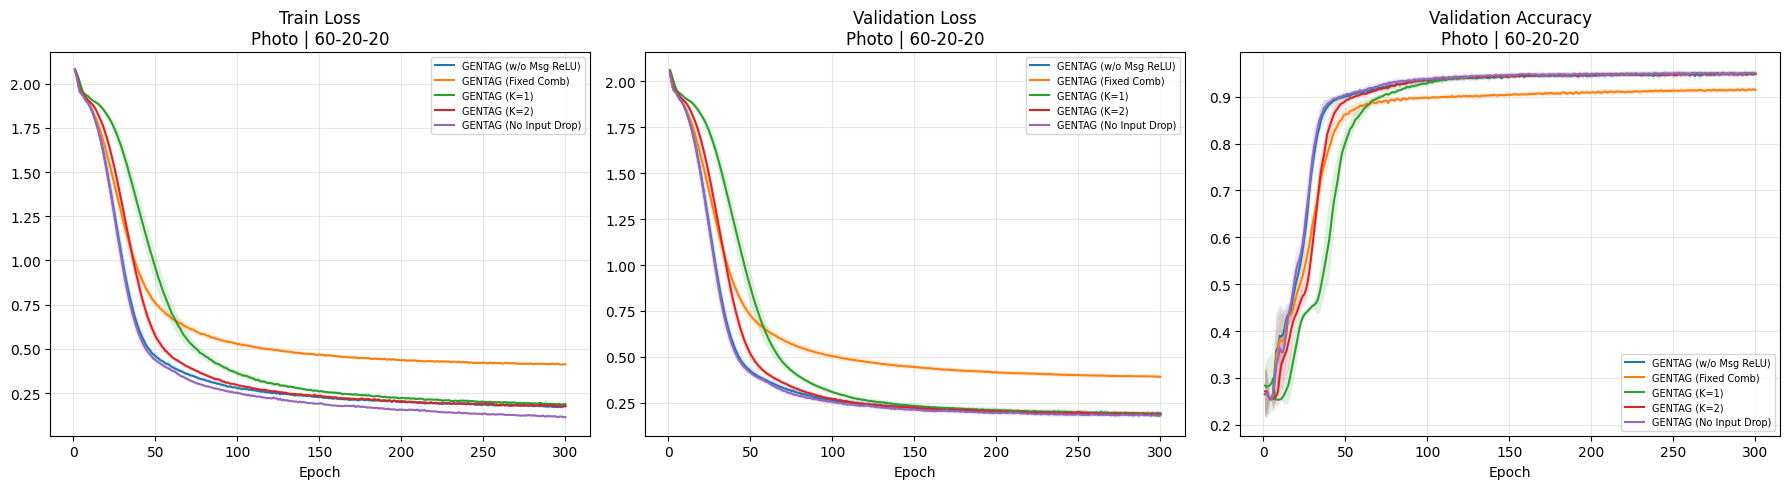

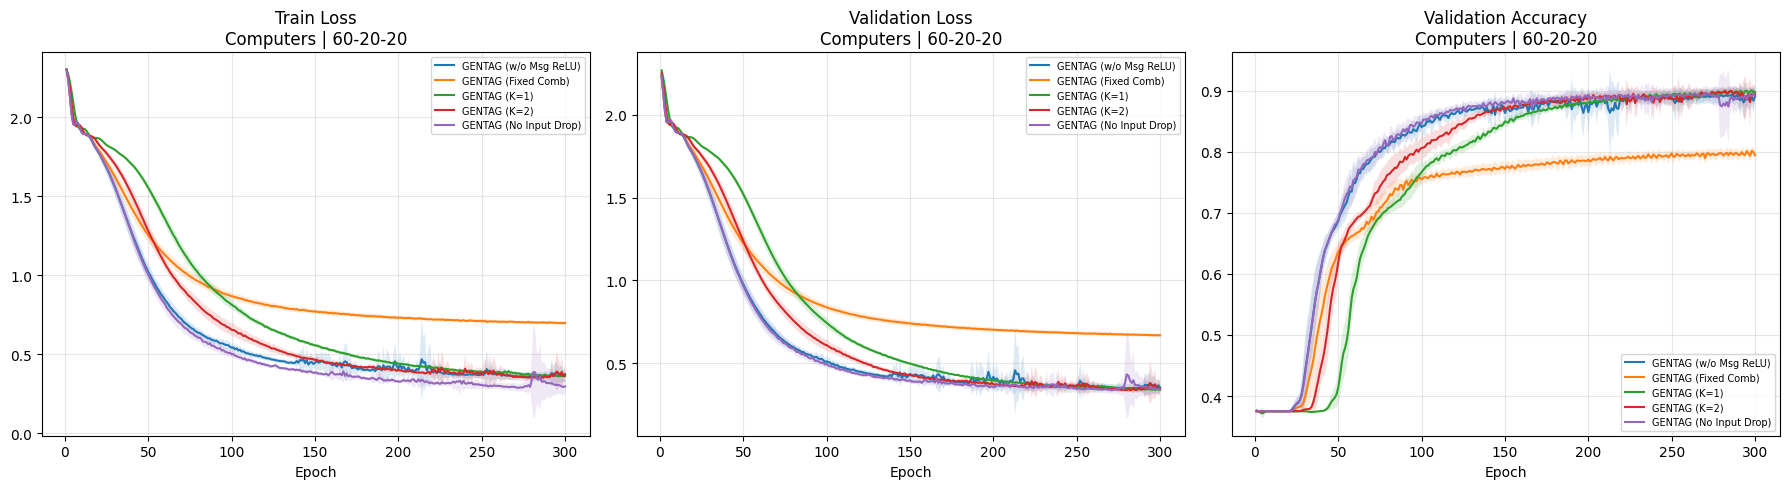


Total time: 7978.5s


In [ ]:
# ablation study
!pip install torch_geometric -q

import os
import random
import json
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import Linear
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

from torch_geometric.datasets import Planetoid, Amazon, CitationFull
from torch_geometric.transforms import NormalizeFeatures
from torch_geometric.nn import MessagePassing
from torch_geometric.nn.conv.gcn_conv import gcn_norm
from torch_geometric.nn.inits import zeros
from torch_geometric.utils import spmm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

SEED = 42

# ---------- hyper-parameters ----------
HIDDEN_DIM   = 64
DROPOUT      = 0.5
LR           = 0.01
WEIGHT_DECAY = 5e-4
MAX_EPOCHS   = 300
PATIENCE     = 30
NUM_RUNS     = 10          # change to 5 for faster results

# ---------- fairness switches ----------
SELECT_BY          = 'val_loss'
NO_DECAY_HOP_COEFS = True

# ---------- architecture constants ----------
K_TAG = 3


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ------------------------------------------------------------
# GENTAG layer
# ------------------------------------------------------------
class TAGConv1(MessagePassing):
    def __init__(self, in_channels, out_channels, K=3, bias=True, normalize=True,
                 use_mlp=False, use_message_relu=True, eps=1e-7,
                 fixed_comb=False, **kwargs):
        kwargs.setdefault('aggr', 'add')
        super().__init__(**kwargs)

        self.K = K
        self.normalize = normalize
        self.use_mlp = use_mlp
        self.use_message_relu = use_message_relu
        self.eps = eps
        self.fixed_comb = fixed_comb

        self.lins = nn.ModuleList([
            Linear(in_channels, out_channels, bias=False) for _ in range(K + 1)
        ])

        if fixed_comb:
            self.register_buffer('comb', torch.ones(K + 1))
        else:
            self.comb = nn.Parameter(torch.ones(K + 1))

        if bias:
            self.bias = nn.Parameter(torch.zeros(out_channels))
        else:
            self.register_parameter('bias', None)

        self.mlp = nn.Sequential(Linear(out_channels, out_channels), nn.ReLU()) if use_mlp else nn.Identity()
        self.reset_parameters()

    def reset_parameters(self):
        for lin in self.lins:
            lin.reset_parameters()
        if not self.fixed_comb:
            nn.init.ones_(self.comb)
        if self.bias is not None:
            zeros(self.bias)

    def forward(self, x, edge_index, edge_weight=None):
        if self.normalize:
            edge_index, edge_weight = gcn_norm(
                edge_index, edge_weight, x.size(self.node_dim),
                improved=False, add_self_loops=False,
                flow=self.flow, dtype=x.dtype
            )

        out = self.comb[0] * self.lins[0](x)
        h = x
        for k in range(1, self.K + 1):
            h = self.propagate(edge_index, x=h, edge_weight=edge_weight)
            out = out + self.comb[k] * self.lins[k](h)

        if self.bias is not None:
            out = out + self.bias
        return self.mlp(out)

    def message(self, x_j, edge_weight):
        msg = x_j if edge_weight is None else edge_weight.view(-1, 1) * x_j
        if self.use_message_relu:
            return msg.relu() + self.eps
        return msg

    def message_and_aggregate(self, adj_t, x):
        return spmm(adj_t, x, reduce=self.aggr)


class GENTAG(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels,
                 K=K_TAG, use_message_relu=True, fixed_comb=False,
                 input_dropout=True):
        super().__init__()
        self.input_dropout = input_dropout
        self.conv1 = TAGConv1(in_channels, hidden_channels, K=K,
                              use_mlp=False, use_message_relu=use_message_relu,
                              fixed_comb=fixed_comb, eps=1e-7)
        self.conv2 = TAGConv1(hidden_channels, out_channels, K=K,
                              use_mlp=False, use_message_relu=use_message_relu,
                              fixed_comb=fixed_comb, eps=1e-7)

    def forward(self, x, edge_index):
        if self.input_dropout:
            x = F.dropout(x, p=DROPOUT, training=self.training)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=DROPOUT, training=self.training)
        return self.conv2(x, edge_index)


# ------------------------------------------------------------
# Ablation variants
# ------------------------------------------------------------
ABLATIONS = {
    'GENTAG (w/o Msg ReLU)':  dict(use_message_relu=False, fixed_comb=False, K=3, input_dropout=True),
    'GENTAG (Fixed Comb)':    dict(use_message_relu=True,  fixed_comb=True,  K=3, input_dropout=True),
    'GENTAG (K=1)':           dict(use_message_relu=True,  fixed_comb=False, K=1, input_dropout=True),
    'GENTAG (K=2)':           dict(use_message_relu=True,  fixed_comb=False, K=2, input_dropout=True),
    'GENTAG (No Input Drop)': dict(use_message_relu=True,  fixed_comb=False, K=3, input_dropout=False),
}


def make_optimizer(model, lr, weight_decay):
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if NO_DECAY_HOP_COEFS and ('comb' in name):
            no_decay.append(param)
        else:
            decay.append(param)
    groups = [{'params': decay, 'weight_decay': weight_decay}]
    if no_decay:
        groups.append({'params': no_decay, 'weight_decay': 0.0})
    return torch.optim.Adam(groups, lr=lr)


def train_one_epoch(model, data, optimizer, criterion):
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()


@torch.no_grad()
def evaluate(model, data, criterion):
    model.eval()
    out = model(data.x, data.edge_index)
    pred = out.argmax(dim=1)
    val_loss = criterion(out[data.val_mask], data.y[data.val_mask]).item()
    val_acc  = (pred[data.val_mask]  == data.y[data.val_mask]).float().mean().item()
    test_acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean().item()
    return val_loss, val_acc, test_acc


def run_with_early_stopping(model, data):
    optimizer = make_optimizer(model, LR, WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()

    best = {'val_loss': float('inf'), 'val_acc': 0.0, 'test_acc': 0.0, 'epoch': 0}
    patience_counter = 0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss = train_one_epoch(model, data, optimizer, criterion)
        val_loss, val_acc, test_acc = evaluate(model, data, criterion)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        improved = (val_loss < best['val_loss']) if SELECT_BY == 'val_loss' else (val_acc > best['val_acc'])
        if improved:
            best = {'val_loss': val_loss, 'val_acc': val_acc, 'test_acc': test_acc, 'epoch': epoch}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                break

    return best['val_acc'], best['test_acc'], history


# ------------------------------------------------------------
# Dataset helpers
# ------------------------------------------------------------
DATASETS = {
    'Citeseer':  ('CitationFull', 'Citeseer'),
    'Pubmed':    ('Planetoid',    'PubMed'),
    'Photo':     ('Amazon',       'Photo'),
    'Computers': ('Amazon',       'Computers'),
}


def load_dataset(name):
    source, ds_name = DATASETS[name]
    if source == 'CitationFull':
        return CitationFull(root=f'./data/{name}', name=ds_name, transform=NormalizeFeatures())
    elif source == 'Planetoid':
        return Planetoid(root=f'./data/{name}', name=ds_name, transform=NormalizeFeatures())
    elif source == 'Amazon':
        return Amazon(root=f'./data/{name}', name=ds_name, transform=NormalizeFeatures())
    else:
        raise ValueError(f"Unknown source: {source}")


def safe_stratify(y):
    counts = np.bincount(y)
    counts = counts[counts > 0]
    return y if counts.min() >= 2 else None


def create_random_split(data, ratios=(0.60, 0.20, 0.20), seed=42):
    train_ratio, val_ratio, test_ratio = ratios
    n = data.num_nodes
    indices = np.arange(n)
    y = data.y.cpu().numpy()

    train_val_idx, test_idx = train_test_split(
        indices, test_size=test_ratio, random_state=seed, stratify=safe_stratify(y)
    )
    train_idx, val_idx = train_test_split(
        train_val_idx,
        test_size=val_ratio / (train_ratio + val_ratio),
        random_state=seed,
        stratify=safe_stratify(y[train_val_idx])
    )

    data = data.clone()
    for mask_name, idx in [('train_mask', train_idx), ('val_mask', val_idx), ('test_mask', test_idx)]:
        mask = torch.zeros(n, dtype=torch.bool)
        mask[idx] = True
        setattr(data, mask_name, mask)
    return data


def get_data(raw_data, run):
    # fresh random 60:20:20 split
    data = create_random_split(raw_data, ratios=(0.60, 0.20, 0.20), seed=SEED + run)
    return data.to(device)


# ------------------------------------------------------------
# Main experiment
# ------------------------------------------------------------
all_results   = {}
all_histories = {}
t0 = time.time()

for ds_name in DATASETS.keys():
    dataset  = load_dataset(ds_name)
    raw_data = dataset[0]
    all_results[ds_name]   = {}
    all_histories[ds_name] = {}

    print(f"\n{'='*70}")
    print(f"Dataset: {ds_name}  ({raw_data.num_nodes} nodes, {dataset.num_classes} classes, {dataset.num_features} feats)")
    print(f"{'='*70}")

    split_results   = {name: [] for name in ABLATIONS}
    split_histories = {name: [] for name in ABLATIONS}

    for run in range(NUM_RUNS):
        data = get_data(raw_data, run)
        print(f"  Run {run+1}/{NUM_RUNS} ...", flush=True)

        for abl_name, kwargs in ABLATIONS.items():
            set_seed(SEED + run)
            model = GENTAG(dataset.num_features, HIDDEN_DIM, dataset.num_classes, **kwargs).to(device)
            _, test_acc, history = run_with_early_stopping(model, data)

            split_results[abl_name].append(test_acc * 100)
            split_histories[abl_name].append(history)
            print(f"    {abl_name:<26} {test_acc*100:6.2f}%", flush=True)

        del data
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    all_results[ds_name]   = {}
    all_histories[ds_name] = split_histories

    print(f"\n--- {ds_name} | 60-20-20 | {time.time()-t0:.0f}s elapsed ---")
    for abl_name, accs in split_results.items():
        accs = np.array(accs)
        mean, std = float(accs.mean()), float(accs.std(ddof=1))
        all_results[ds_name][abl_name] = (mean, std)
        print(f"{abl_name:<26} {mean:6.2f} ± {std:5.2f}")


# ------------------------------------------------------------
# Final tables
# ------------------------------------------------------------
print("\n\n" + "="*70)
print("FINAL RESULTS (Test Accuracy %)")
print("="*70)

for ds, d in all_results.items():
    print(f"\n### {ds}")
    df = pd.DataFrame({
        'Accuracy (%)': {m: f"{mu:.2f} ± {sd:.2f}" for m, (mu, sd) in d.items()}
    })
    print(df.to_string())

# Save results
with open('results_gentag_ablation.json', 'w') as f:
    json.dump(all_results, f, indent=2)
print("\nResults saved to results_gentag_ablation.json")


# ------------------------------------------------------------
# Plot average curves
# ------------------------------------------------------------
def pad_and_average(histories, key):
    max_len = max(len(h[key]) for h in histories)
    padded = []
    for h in histories:
        arr = np.array(h[key])
        if len(arr) < max_len:
            arr = np.pad(arr, (0, max_len - len(arr)), mode='edge')
        padded.append(arr)
    return np.mean(padded, axis=0), np.std(padded, axis=0)


def plot_curves(histories_dict, dataset_name):
    models = list(histories_dict.keys())
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    metrics = [
        ('train_loss', 'Train Loss'),
        ('val_loss',   'Validation Loss'),
        ('val_acc',    'Validation Accuracy')
    ]

    for ax, (key, title) in zip(axes, metrics):
        for model_name in models:
            mean, std = pad_and_average(histories_dict[model_name], key)
            epochs = np.arange(1, len(mean) + 1)
            ax.plot(epochs, mean, label=model_name)
            ax.fill_between(epochs, mean - std, mean + std, alpha=0.15)
        ax.set_title(f"{title}\n{dataset_name} | 60-20-20")
        ax.set_xlabel("Epoch")
        ax.legend(fontsize=7)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


for ds_name in all_histories:
    plot_curves(all_histories[ds_name], ds_name)

print(f"\nTotal time: {time.time() - t0:.1f}s")

Using device: cuda


Processing...
Done!



Dataset: Cornell  (183 nodes, 5 classes, 1703 feats)
  Run 1/10 ...
    GENTAG (w/o Msg ReLU)       72.97%
    GENTAG (Fixed Comb)         72.97%
    GENTAG (K=1)                72.97%
    GENTAG (K=2)                72.97%
    GENTAG (No Input Drop)      72.97%
  Run 2/10 ...
    GENTAG (w/o Msg ReLU)       83.78%
    GENTAG (Fixed Comb)         83.78%
    GENTAG (K=1)                86.49%
    GENTAG (K=2)                83.78%
    GENTAG (No Input Drop)      83.78%
  Run 3/10 ...
    GENTAG (w/o Msg ReLU)       72.97%
    GENTAG (Fixed Comb)         72.97%
    GENTAG (K=1)                72.97%
    GENTAG (K=2)                75.68%
    GENTAG (No Input Drop)      72.97%
  Run 4/10 ...
    GENTAG (w/o Msg ReLU)       83.78%
    GENTAG (Fixed Comb)         81.08%
    GENTAG (K=1)                75.68%
    GENTAG (K=2)                81.08%
    GENTAG (No Input Drop)      83.78%
  Run 5/10 ...
    GENTAG (w/o Msg ReLU)       86.49%
    GENTAG (Fixed Comb)         86.49%
    GENTAG (K


Dataset: Texas  (183 nodes, 5 classes, 1703 feats)
  Run 1/10 ...


Processing...
Done!


    GENTAG (w/o Msg ReLU)       83.78%
    GENTAG (Fixed Comb)         75.68%
    GENTAG (K=1)                86.49%
    GENTAG (K=2)                75.68%
    GENTAG (No Input Drop)      83.78%
  Run 2/10 ...
    GENTAG (w/o Msg ReLU)       91.89%
    GENTAG (Fixed Comb)         89.19%
    GENTAG (K=1)                91.89%
    GENTAG (K=2)                91.89%
    GENTAG (No Input Drop)      91.89%
  Run 3/10 ...
    GENTAG (w/o Msg ReLU)       78.38%
    GENTAG (Fixed Comb)         72.97%
    GENTAG (K=1)                81.08%
    GENTAG (K=2)                81.08%
    GENTAG (No Input Drop)      81.08%
  Run 4/10 ...
    GENTAG (w/o Msg ReLU)       78.38%
    GENTAG (Fixed Comb)         78.38%
    GENTAG (K=1)                81.08%
    GENTAG (K=2)                81.08%
    GENTAG (No Input Drop)      78.38%
  Run 5/10 ...
    GENTAG (w/o Msg ReLU)       91.89%
    GENTAG (Fixed Comb)         86.49%
    GENTAG (K=1)                94.59%
    GENTAG (K=2)                97.30%
    


Dataset: Wisconsin  (251 nodes, 5 classes, 1703 feats)
  Run 1/10 ...


Processing...
Done!


    GENTAG (w/o Msg ReLU)       86.27%
    GENTAG (Fixed Comb)         86.27%
    GENTAG (K=1)                92.16%
    GENTAG (K=2)                90.20%
    GENTAG (No Input Drop)      90.20%
  Run 2/10 ...
    GENTAG (w/o Msg ReLU)       84.31%
    GENTAG (Fixed Comb)         82.35%
    GENTAG (K=1)                86.27%
    GENTAG (K=2)                84.31%
    GENTAG (No Input Drop)      80.39%
  Run 3/10 ...
    GENTAG (w/o Msg ReLU)       84.31%
    GENTAG (Fixed Comb)         84.31%
    GENTAG (K=1)                88.24%
    GENTAG (K=2)                90.20%
    GENTAG (No Input Drop)      86.27%
  Run 4/10 ...
    GENTAG (w/o Msg ReLU)       78.43%
    GENTAG (Fixed Comb)         80.39%
    GENTAG (K=1)                86.27%
    GENTAG (K=2)                80.39%
    GENTAG (No Input Drop)      78.43%
  Run 5/10 ...
    GENTAG (w/o Msg ReLU)       76.47%
    GENTAG (Fixed Comb)         78.43%
    GENTAG (K=1)                74.51%
    GENTAG (K=2)                78.43%
    

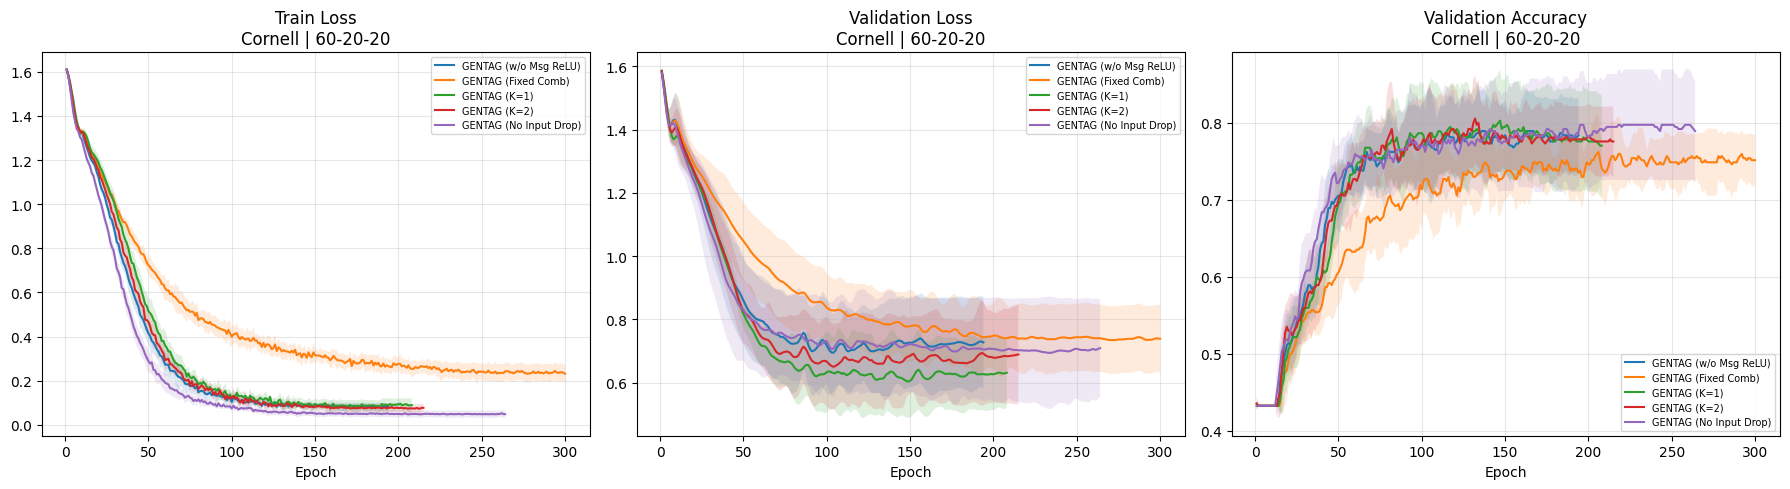

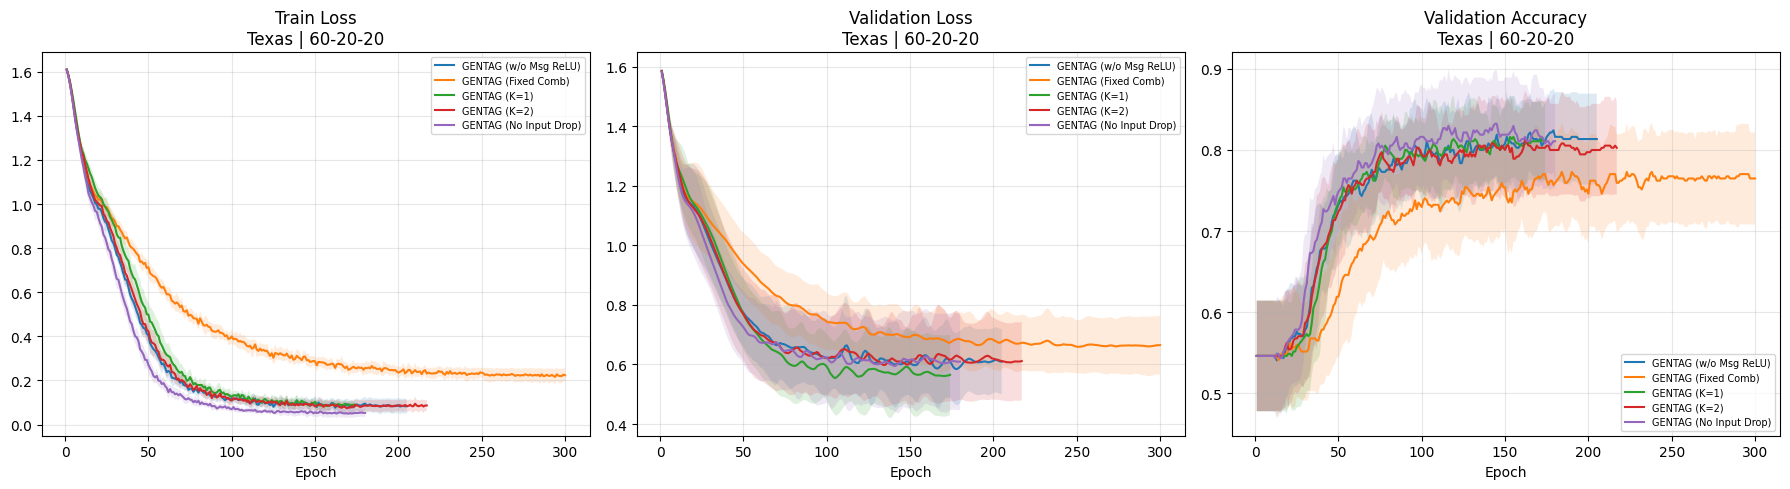

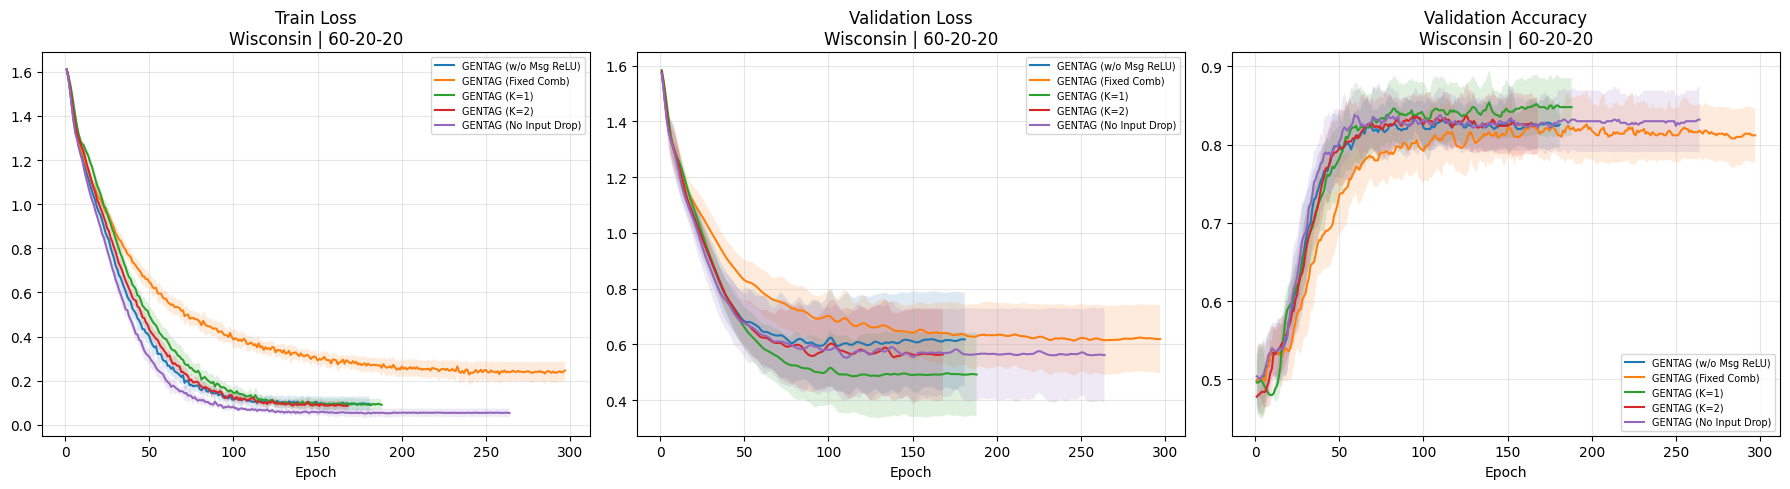


Total time: 237.2s


In [ ]:
# ablation study
!pip install torch_geometric -q

import os
import random
import json
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import Linear
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

from torch_geometric.datasets import WebKB
from torch_geometric.transforms import NormalizeFeatures
from torch_geometric.nn import MessagePassing
from torch_geometric.nn.conv.gcn_conv import gcn_norm
from torch_geometric.nn.inits import zeros
from torch_geometric.utils import spmm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

SEED = 42

# ---------- hyper-parameters ----------
HIDDEN_DIM   = 64
DROPOUT      = 0.5
LR           = 0.01
WEIGHT_DECAY = 5e-4
MAX_EPOCHS   = 300
PATIENCE     = 30
NUM_RUNS     = 10          # change to 5 for faster results

# ---------- fairness switches ----------
SELECT_BY          = 'val_loss'
NO_DECAY_HOP_COEFS = True

# ---------- architecture constants ----------
K_TAG = 3


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ------------------------------------------------------------
# GENTAG layer
# ------------------------------------------------------------
class TAGConv1(MessagePassing):
    def __init__(self, in_channels, out_channels, K=3, bias=True, normalize=True,
                 use_mlp=False, use_message_relu=True, eps=1e-7,
                 fixed_comb=False, **kwargs):
        kwargs.setdefault('aggr', 'add')
        super().__init__(**kwargs)

        self.K = K
        self.normalize = normalize
        self.use_mlp = use_mlp
        self.use_message_relu = use_message_relu
        self.eps = eps
        self.fixed_comb = fixed_comb

        self.lins = nn.ModuleList([
            Linear(in_channels, out_channels, bias=False) for _ in range(K + 1)
        ])

        if fixed_comb:
            self.register_buffer('comb', torch.ones(K + 1))
        else:
            self.comb = nn.Parameter(torch.ones(K + 1))

        if bias:
            self.bias = nn.Parameter(torch.zeros(out_channels))
        else:
            self.register_parameter('bias', None)

        self.mlp = nn.Sequential(Linear(out_channels, out_channels), nn.ReLU()) if use_mlp else nn.Identity()
        self.reset_parameters()

    def reset_parameters(self):
        for lin in self.lins:
            lin.reset_parameters()
        if not self.fixed_comb:
            nn.init.ones_(self.comb)
        if self.bias is not None:
            zeros(self.bias)

    def forward(self, x, edge_index, edge_weight=None):
        if self.normalize:
            edge_index, edge_weight = gcn_norm(
                edge_index, edge_weight, x.size(self.node_dim),
                improved=False, add_self_loops=False,
                flow=self.flow, dtype=x.dtype
            )

        out = self.comb[0] * self.lins[0](x)
        h = x
        for k in range(1, self.K + 1):
            h = self.propagate(edge_index, x=h, edge_weight=edge_weight)
            out = out + self.comb[k] * self.lins[k](h)

        if self.bias is not None:
            out = out + self.bias
        return self.mlp(out)

    def message(self, x_j, edge_weight):
        msg = x_j if edge_weight is None else edge_weight.view(-1, 1) * x_j
        if self.use_message_relu:
            return msg.relu() + self.eps
        return msg

    def message_and_aggregate(self, adj_t, x):
        return spmm(adj_t, x, reduce=self.aggr)


class GENTAG(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels,
                 K=K_TAG, use_message_relu=True, fixed_comb=False,
                 input_dropout=True):
        super().__init__()
        self.input_dropout = input_dropout
        self.conv1 = TAGConv1(in_channels, hidden_channels, K=K,
                              use_mlp=False, use_message_relu=use_message_relu,
                              fixed_comb=fixed_comb, eps=1e-7)
        self.conv2 = TAGConv1(hidden_channels, out_channels, K=K,
                              use_mlp=False, use_message_relu=use_message_relu,
                              fixed_comb=fixed_comb, eps=1e-7)

    def forward(self, x, edge_index):
        if self.input_dropout:
            x = F.dropout(x, p=DROPOUT, training=self.training)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=DROPOUT, training=self.training)
        return self.conv2(x, edge_index)


# ------------------------------------------------------------
# Ablation variants
# ------------------------------------------------------------
ABLATIONS = {
    'GENTAG (w/o Msg ReLU)':  dict(use_message_relu=False, fixed_comb=False, K=3, input_dropout=True),
    'GENTAG (Fixed Comb)':    dict(use_message_relu=True,  fixed_comb=True,  K=3, input_dropout=True),
    'GENTAG (K=1)':           dict(use_message_relu=True,  fixed_comb=False, K=1, input_dropout=True),
    'GENTAG (K=2)':           dict(use_message_relu=True,  fixed_comb=False, K=2, input_dropout=True),
    'GENTAG (No Input Drop)': dict(use_message_relu=True,  fixed_comb=False, K=3, input_dropout=False),
}


def make_optimizer(model, lr, weight_decay):
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if NO_DECAY_HOP_COEFS and ('comb' in name):
            no_decay.append(param)
        else:
            decay.append(param)
    groups = [{'params': decay, 'weight_decay': weight_decay}]
    if no_decay:
        groups.append({'params': no_decay, 'weight_decay': 0.0})
    return torch.optim.Adam(groups, lr=lr)


def train_one_epoch(model, data, optimizer, criterion):
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()


@torch.no_grad()
def evaluate(model, data, criterion):
    model.eval()
    out = model(data.x, data.edge_index)
    pred = out.argmax(dim=1)
    val_loss = criterion(out[data.val_mask], data.y[data.val_mask]).item()
    val_acc  = (pred[data.val_mask]  == data.y[data.val_mask]).float().mean().item()
    test_acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean().item()
    return val_loss, val_acc, test_acc


def run_with_early_stopping(model, data):
    optimizer = make_optimizer(model, LR, WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()

    best = {'val_loss': float('inf'), 'val_acc': 0.0, 'test_acc': 0.0, 'epoch': 0}
    patience_counter = 0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss = train_one_epoch(model, data, optimizer, criterion)
        val_loss, val_acc, test_acc = evaluate(model, data, criterion)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        improved = (val_loss < best['val_loss']) if SELECT_BY == 'val_loss' else (val_acc > best['val_acc'])
        if improved:
            best = {'val_loss': val_loss, 'val_acc': val_acc, 'test_acc': test_acc, 'epoch': epoch}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                break

    return best['val_acc'], best['test_acc'], history


# ------------------------------------------------------------
# Dataset helpers
# ------------------------------------------------------------
DATASETS = {
    'Cornell':   'Cornell',
    'Texas':     'Texas',
    'Wisconsin': 'Wisconsin',
}


def load_dataset(name):
    return WebKB(root=f'./data/{name}', name=DATASETS[name], transform=NormalizeFeatures())


def safe_stratify(y):
    counts = np.bincount(y)
    counts = counts[counts > 0]
    return y if counts.min() >= 2 else None


def create_random_split(data, ratios=(0.60, 0.20, 0.20), seed=42):
    train_ratio, val_ratio, test_ratio = ratios
    n = data.num_nodes
    indices = np.arange(n)
    y = data.y.cpu().numpy()

    train_val_idx, test_idx = train_test_split(
        indices, test_size=test_ratio, random_state=seed, stratify=safe_stratify(y)
    )
    train_idx, val_idx = train_test_split(
        train_val_idx,
        test_size=val_ratio / (train_ratio + val_ratio),
        random_state=seed,
        stratify=safe_stratify(y[train_val_idx])
    )

    data = data.clone()
    for mask_name, idx in [('train_mask', train_idx), ('val_mask', val_idx), ('test_mask', test_idx)]:
        mask = torch.zeros(n, dtype=torch.bool)
        mask[idx] = True
        setattr(data, mask_name, mask)
    return data


def get_data(raw_data, run):
    # fresh random 60:20:20 split
    data = create_random_split(raw_data, ratios=(0.60, 0.20, 0.20), seed=SEED + run)
    return data.to(device)


# ------------------------------------------------------------
# Main experiment
# ------------------------------------------------------------
all_results   = {}
all_histories = {}
t0 = time.time()

for ds_name in DATASETS.keys():
    dataset  = load_dataset(ds_name)
    raw_data = dataset[0]
    all_results[ds_name]   = {}
    all_histories[ds_name] = {}

    print(f"\n{'='*70}")
    print(f"Dataset: {ds_name}  ({raw_data.num_nodes} nodes, {dataset.num_classes} classes, {dataset.num_features} feats)")
    print(f"{'='*70}")

    split_results   = {name: [] for name in ABLATIONS}
    split_histories = {name: [] for name in ABLATIONS}

    for run in range(NUM_RUNS):
        data = get_data(raw_data, run)
        print(f"  Run {run+1}/{NUM_RUNS} ...", flush=True)

        for abl_name, kwargs in ABLATIONS.items():
            set_seed(SEED + run)
            model = GENTAG(dataset.num_features, HIDDEN_DIM, dataset.num_classes, **kwargs).to(device)
            _, test_acc, history = run_with_early_stopping(model, data)

            split_results[abl_name].append(test_acc * 100)
            split_histories[abl_name].append(history)
            print(f"    {abl_name:<26} {test_acc*100:6.2f}%", flush=True)

        del data
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    all_results[ds_name]   = {}
    all_histories[ds_name] = split_histories

    print(f"\n--- {ds_name} | 60-20-20 | {time.time()-t0:.0f}s elapsed ---")
    for abl_name, accs in split_results.items():
        accs = np.array(accs)
        mean, std = float(accs.mean()), float(accs.std(ddof=1))
        all_results[ds_name][abl_name] = (mean, std)
        print(f"{abl_name:<26} {mean:6.2f} ± {std:5.2f}")


# ------------------------------------------------------------
# Final tables
# ------------------------------------------------------------
print("\n\n" + "="*70)
print("FINAL RESULTS (Test Accuracy %)")
print("="*70)

for ds, d in all_results.items():
    print(f"\n### {ds}")
    df = pd.DataFrame({
        'Accuracy (%)': {m: f"{mu:.2f} ± {sd:.2f}" for m, (mu, sd) in d.items()}
    })
    print(df.to_string())

# Save results
with open('results_gentag_ablation.json', 'w') as f:
    json.dump(all_results, f, indent=2)
print("\nResults saved to results_gentag_ablation.json")


# ------------------------------------------------------------
# Plot average curves
# ------------------------------------------------------------
def pad_and_average(histories, key):
    max_len = max(len(h[key]) for h in histories)
    padded = []
    for h in histories:
        arr = np.array(h[key])
        if len(arr) < max_len:
            arr = np.pad(arr, (0, max_len - len(arr)), mode='edge')
        padded.append(arr)
    return np.mean(padded, axis=0), np.std(padded, axis=0)


def plot_curves(histories_dict, dataset_name):
    models = list(histories_dict.keys())
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    metrics = [
        ('train_loss', 'Train Loss'),
        ('val_loss',   'Validation Loss'),
        ('val_acc',    'Validation Accuracy')
    ]

    for ax, (key, title) in zip(axes, metrics):
        for model_name in models:
            mean, std = pad_and_average(histories_dict[model_name], key)
            epochs = np.arange(1, len(mean) + 1)
            ax.plot(epochs, mean, label=model_name)
            ax.fill_between(epochs, mean - std, mean + std, alpha=0.15)
        ax.set_title(f"{title}\n{dataset_name} | 60-20-20")
        ax.set_xlabel("Epoch")
        ax.legend(fontsize=7)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


for ds_name in all_histories:
    plot_curves(all_histories[ds_name], ds_name)

print(f"\nTotal time: {time.time() - t0:.1f}s")